# Clustering Analysis of US Crime Data (Total: 70 pts)

**Objective**: Perform clustering analysis on the US Crime dataset using four clustering algorithms: KMeans, MiniBatchKMeans, DBSCAN, and Gaussian Mixture Models (GMM).

The goal is to analyze how well each algorithm clusters the data and to explore how crime patterns change over the years.

In [1]:
# Import all libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, MiniBatchKMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

## Data Loading and Preparation (5 pts)

In [178]:
# Load the dataset "US_Crime_DataSet.csv" into a DataFrame
df_crimes = pd.read_csv('US_Crime_DataSet.csv', low_memory=False)

# Display the first few rows
print(df_crimes.head(5))

# Display the data type of each column
print(df_crimes.dtypes)

   Record ID Agency Code Agency Name       Agency Type       City   State  \
0          1     AK00101   Anchorage  Municipal Police  Anchorage  Alaska   
1          2     AK00101   Anchorage  Municipal Police  Anchorage  Alaska   
2          3     AK00101   Anchorage  Municipal Police  Anchorage  Alaska   
3          4     AK00101   Anchorage  Municipal Police  Anchorage  Alaska   
4          5     AK00101   Anchorage  Municipal Police  Anchorage  Alaska   

   Year    Month  Incident              Crime Type  ... Victim Ethnicity  \
0  1980  January         1  Murder or Manslaughter  ...          Unknown   
1  1980    March         1  Murder or Manslaughter  ...          Unknown   
2  1980    March         2  Murder or Manslaughter  ...          Unknown   
3  1980    April         1  Murder or Manslaughter  ...          Unknown   
4  1980    April         2  Murder or Manslaughter  ...          Unknown   

  Perpetrator Sex  Perpetrator Age               Perpetrator Race  \
0          

### Group by Year and Count the Number of Crimes

In [3]:
# Group by year and count the number of crimes
years = df_crimes.groupby('Year')

crime_counts_yearwise = years.size()

# Display the results
print(crime_counts_yearwise)

Year
1980    23092
1981    21208
1982    20544
1983    19653
1984    18093
1985    18384
1986    20125
1987    18783
1988    18779
1989    19868
1990    21246
1991    22657
1992    23793
1993    24335
1994    23246
1995    21179
1996    18969
1997    17794
1998    16061
1999    14621
2000    14671
2001    15803
2002    16268
2003    16512
2004    16233
2005    16836
2006    17275
2007    17303
2008    15595
2009    15840
2010    15121
2011    14756
2012    15033
2013    14445
2014    14331
dtype: int64


### Preprocessing the Data (15 pts)
Handle missing values and prepare the data for clustering.

**Note on missing values:** This dataset has no empty cells. Instead, missing information is recorded with placeholder values:
- `Victim Age` uses **998** to mean the age is unknown.
- Categorical columns such as `Weapon` use the text **"Unknown"**.

In [179]:
# Check for missing values (1 pt)
missing_idx = df_crimes.index[df_crimes.isin(['Unknown', '998']).any(axis=1)]

# print number of entries with a missing value
print(len(missing_idx))

482601


In [19]:
# Handle missing values (6 pts)
# 1. Replace Victim Age values of 998 with NaN, then fill them with the median Victim Age.
# 2. Keep "Unknown" in the categorical columns as its own category (no change needed).

df_crimes['Victim Age'] = df_crimes['Victim Age'].replace(998, np.nan)
df_crimes['Victim Age'] = df_crimes['Victim Age'].fillna(df_crimes['Victim Age'].median())

In [22]:
# Define the numeric features for clustering
numeric_features = ['Year', 'Victim Age', 'Victim Count', 'Incident']  # You may adjust this list

# Define the categorical features for clustering
categorical_features = ['Crime Type', 'Weapon', 'State']

# Note: 'State' is used instead of 'Agency Name'. 'Agency Name' has over 9,000 unique values,
# which would create too many columns after one-hot encoding and can run out of memory.

# Use a ColumnTransformer to standardize the numeric features and one-hot encode the categorical features (4 pts)
# Use OneHotEncoder(handle_unknown='ignore', sparse_output=False)
preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', StandardScaler(), numeric_features),
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ]
)

# Fit the preprocessor on the full dataset and transform it
X = preprocessor.fit_transform(df_crimes) # YOUR CODE

### Sample the Data (4 pts)
Clustering the full dataset is slow, so take a random sample of the data and use it for the rest of the assignment. Use `frac=0.02` and `random_state=42`.

In [24]:
# Step 1: Sample the data (use frac=0.02 and random_state=42)
df_sample = df_crimes.sample(frac=0.02, random_state=42)

# Step 2: Transform the sample using the preprocessor fitted above
X_sample = preprocessor.fit_transform(df_sample) # YOUR CODE


### Dimensionality Reduction (3 pts)
Reduce the sampled data to **2 principal components**. All of the clustering and plotting below uses this PCA-reduced data.

In [25]:
# Step 3: Reduce the sampled data to 2 components with PCA
pca = PCA(n_components=2)
X_sample_reduced = pca.fit_transform(X_sample)


### Finding the Optimal K Using the Elbow Method and Silhouette Scores (7 pts)
Define a range of K values and evaluate each one (3 pts for fitting, 2 pts for the elbow plot, 2 pts for the silhouette plot).

2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20


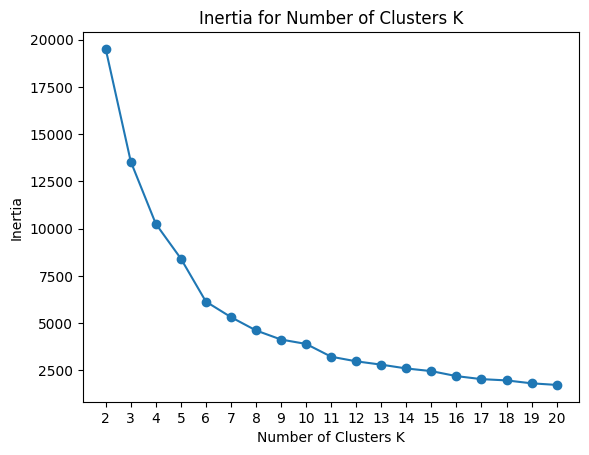

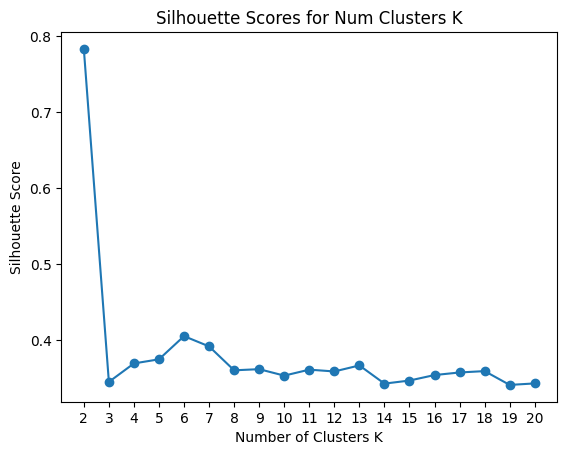

In [36]:
# Step 4: Define a range of K values and initialize lists for the inertia and silhouette scores
k_values = range(2, 21)  # You may adjust this range
inertia = []
silhouette_scores = []

# Step 5: Fit KMeans for each value of K on the PCA-reduced data (X_sample_reduced)
for k in k_values:
    print(k)
    # YOUR CODE
    model = KMeans(n_clusters=k)
    model.fit(X_sample_reduced)

    inertia.append(model.inertia_)
    score = silhouette_score(X_sample_reduced, model.labels_)
    silhouette_scores.append(score)

# Step 6: Plot the elbow method (K vs. inertia)
plt.figure()
plt.plot(k_values, inertia, marker='o')
plt.xlabel('Number of Clusters K')
plt.ylabel('Inertia')
plt.title('Inertia for Number of Clusters K')
plt.xticks(k_values)
plt.show()


# Step 7: Plot the silhouette scores (K vs. silhouette score)
plt.figure()
plt.plot(k_values, silhouette_scores, marker='o')
plt.xlabel('Number of Clusters K')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Scores for Num Clusters K')
plt.xticks(k_values)
plt.show()


**Question (3 pts):** What value of K did you choose based on the analysis above (1 pt)? How did you decide (2 pts)?

Answer: I chose a k value of 6. The silhouette score of all values of k are around a similar range outside of the outlier of k=2. I decided to go with k=6 as it is where the intertia stops decreasig by large amounts and has a slightly higher silhouette score than the k-values around it. In general, the points aren't clustered very well regardless of number of clusters as the silhouette score is low and inertia is fairly high.

### Apply the Clustering Algorithms (12 pts, 3 pts each)
Using the optimal K from above, apply each clustering algorithm to the PCA-reduced data (`X_sample_reduced`).

In [174]:
# Set the optimal number of clusters
optimal_k = 6 # YOUR CODE

# KMeans
kmeans = KMeans(n_clusters=optimal_k)
kmeans.fit(X_sample_reduced)
kmeans_pred = kmeans.predict(X_sample_reduced)

# MiniBatchKMeans
minibatch_kmeans = MiniBatchKMeans(n_clusters=optimal_k)
minibatch_kmeans.fit(X_sample_reduced)
minibatch_kmeans_pred = minibatch_kmeans.predict(X_sample_reduced)

# DBSCAN (you may need to tune eps and min_samples)
dbscan = DBSCAN(eps=0.35, min_samples=5)
dbscan_pred = dbscan.fit_predict(X_sample_reduced)

# Gaussian Mixture Model
gmm = GaussianMixture(n_components=optimal_k)
gmm.fit(X_sample_reduced)
gmm_pred = gmm.predict(X_sample_reduced)

### Visualizing the Clusters (8 pts, 2 pts each)

Plot the clusters found by each algorithm on the two PCA components, coloring each point by its cluster label.

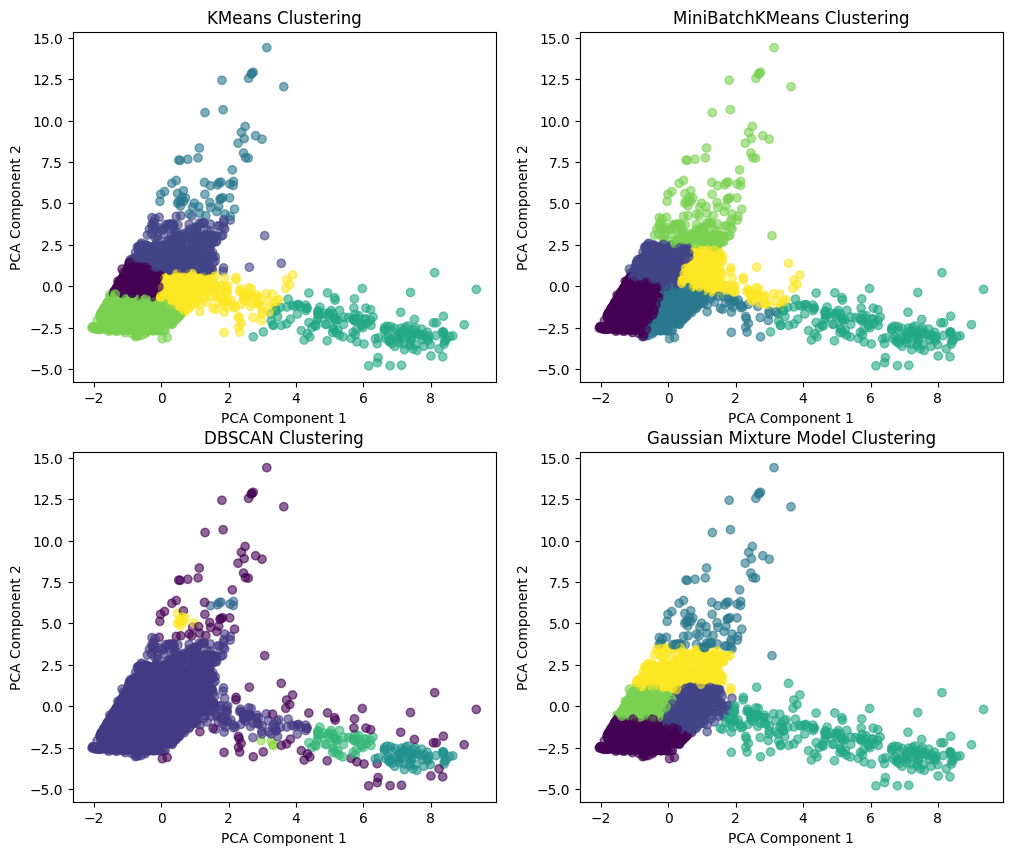

In [175]:
plt.figure(figsize=(12, 10))

# KMeans clusters
plt.subplot(2, 2, 1)
plt.scatter(
    X_sample_reduced[:, 0],
    X_sample_reduced[:, 1],
    c=kmeans_pred,
    alpha=0.6
)
plt.title('KMeans Clustering')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')

# MiniBatchKMeans clusters
plt.subplot(2, 2, 2)
plt.scatter(
    X_sample_reduced[:, 0],
    X_sample_reduced[:, 1],
    c=minibatch_kmeans_pred,
    alpha=0.6
)
plt.title('MiniBatchKMeans Clustering')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')

# DBSCAN clusters
plt.subplot(2, 2, 3)
plt.scatter(
    X_sample_reduced[:, 0],
    X_sample_reduced[:, 1],
    c=dbscan_pred,
    alpha=0.6
)
plt.title('DBSCAN Clustering')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')

# GMM clusters
plt.subplot(2, 2, 4)
plt.scatter(
    X_sample_reduced[:, 0],
    X_sample_reduced[:, 1],
    c=gmm_pred,
    alpha=0.6
)
plt.title('Gaussian Mixture Model Clustering')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')

plt.show()

Write a brief analysis comparing KMeans, DBSCAN, and GMM. Include their strengths, weaknesses, and when to use each one.

Answer:
KMeans has easiest interpretability and computational efficiency of the 3 clustering algorithms. The issue is that the number of clusters need to be specified beforehand so it can sometimes be challenging how many clusters to have. Also KMeans does not work with clusters that are not similar sized or a spherical shape. It's best to use KMeans when the data has clear separated groups that are in a spherical shape.

DBSCAN's strengths are that is doesn't need to specify the number of clusters, can identify noisy points or outliers, and can find arbitraily shaped clusters. It's weakness is that it has 2 hyperparameters that need to be specified which are epsilon and minpts and is sensitive to the values of these parameters. It also struggles when the density of clusters varies. DBSCAN is best used when the data contains noise or outliers and the shape of clusters is unknown.

GMM performs soft clustering so its strengths are that it can handle overlapping clusters and can model elliptical clusters. Its weakness is that it still requires the number of clusters to be chosen, assumes the data is in a Gaussian like structure, is sensitive to initialization, and is more computationally expensive than the other algorithms. GMM is best used when clusters overlap or are elliptical in shape.

### Year-wise Analysis (4 pts, 1 pt each)
Group the sampled data by year and cluster. First, add each algorithm's cluster labels to `df_sample` as new columns. Then count the number of crimes in each cluster for each year.

In [176]:
df_sample['KMeans'] = kmeans_pred
df_sample['MiniBatchKMeans'] = minibatch_kmeans_pred
df_sample['DBSCAN'] = dbscan_pred
df_sample['GMM'] = gmm_pred

# Group by Year and KMeans cluster
year_cluster_counts_kmeans = df_sample.groupby(['Year', 'KMeans']).size().unstack(fill_value=0)

# Group by Year and MiniBatchKMeans cluster
year_cluster_counts_minibatch = df_sample.groupby(['Year', 'MiniBatchKMeans']).size().unstack(fill_value=0)

# Group by Year and DBSCAN cluster
year_cluster_counts_dbscan = df_sample.groupby(['Year', 'DBSCAN']).size().unstack(fill_value=0)

# Group by Year and GMM cluster
year_cluster_counts_gmm =df_sample.groupby(['Year', 'GMM']).size().unstack(fill_value=0)


### Visualize the Year-wise Cluster Counts (8 pts: 4 pts for the plotting function, 1 pt for each of the 4 plots)

Create plots showing how many crimes fall into each cluster in each year. You may use bar plots or line plots.

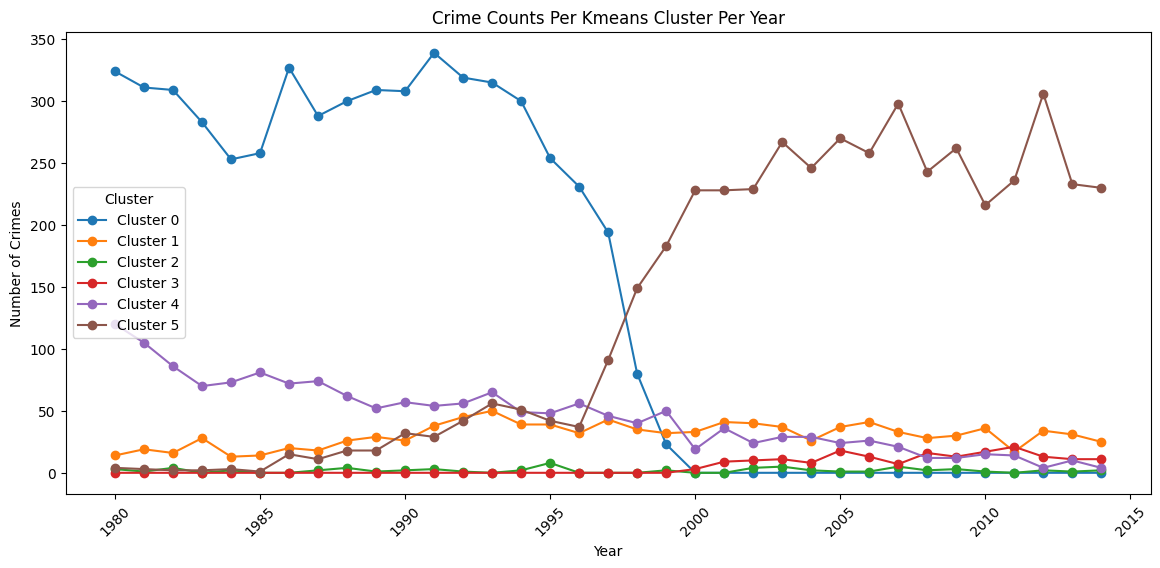

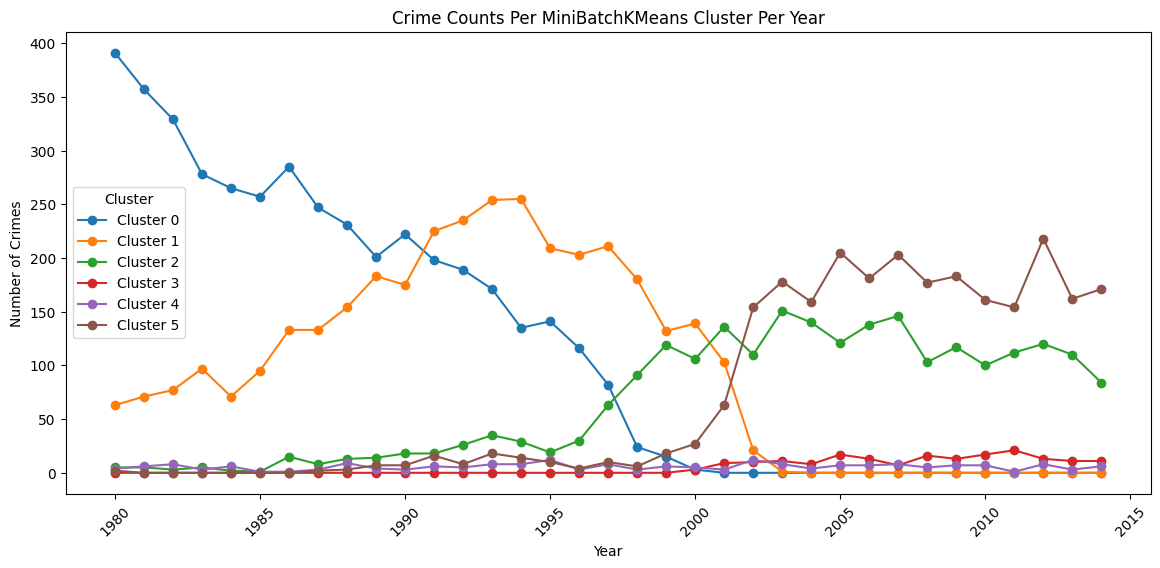

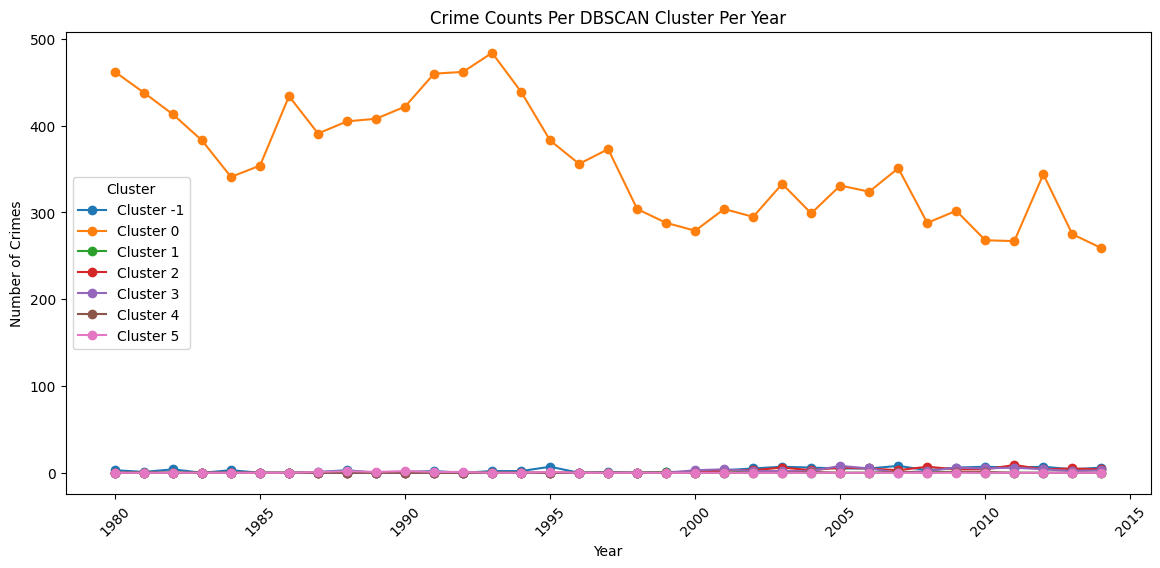

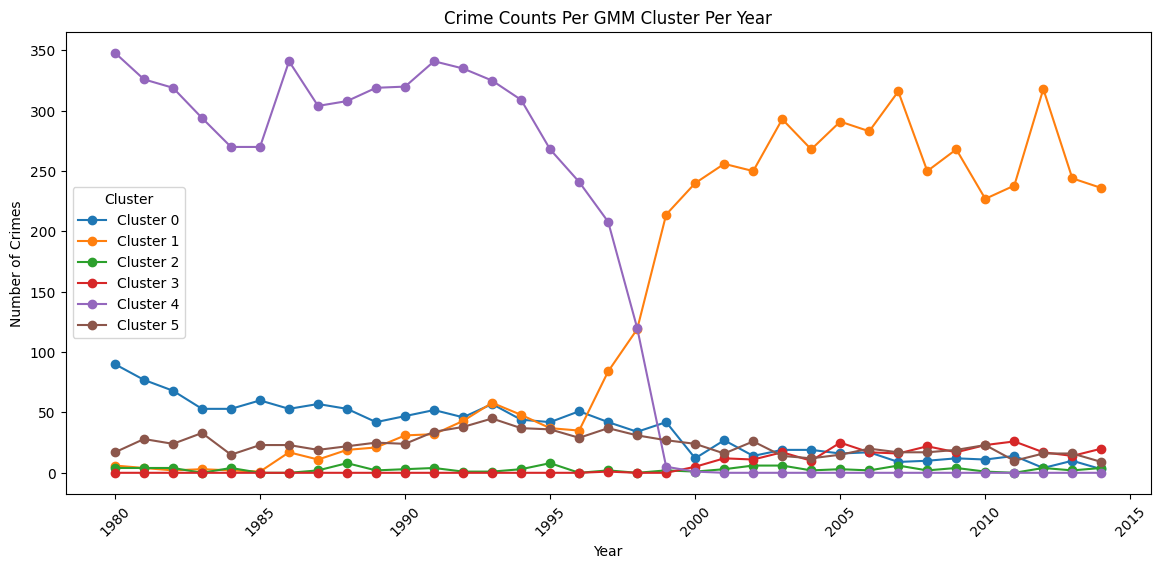

In [177]:
# Function to plot the year-wise cluster counts
def plot_yearwise_analysis(year_cluster_counts, title):
    # YOUR CODE
    plt.figure(figsize=(14, 6))

    for cluster in year_cluster_counts.columns:
        plt.plot(year_cluster_counts.index, year_cluster_counts[cluster], marker='o', label=f"Cluster {cluster}")

    plt.title(title)
    plt.xlabel('Year')
    plt.ylabel('Number of Crimes')
    plt.xticks(rotation=45)
    plt.legend(title='Cluster', loc='center left')
    plt.show()

# Plot for KMeans
plot_yearwise_analysis(year_cluster_counts_kmeans, 'Crime Counts Per Kmeans Cluster Per Year')


# Plot for MiniBatchKMeans
plot_yearwise_analysis(year_cluster_counts_minibatch, 'Crime Counts Per MiniBatchKMeans Cluster Per Year')


# Plot for DBSCAN
plot_yearwise_analysis(year_cluster_counts_dbscan, 'Crime Counts Per DBSCAN Cluster Per Year')


# Plot for GMM
plot_yearwise_analysis(year_cluster_counts_gmm, 'Crime Counts Per GMM Cluster Per Year')


Write a brief summary of your analysis. (5 pts)

Answer:

Kmeans clustering appears to have separated the data into 2 distinct clusters. Cluster 0 mainly contains crimes that happened before the year 2000 while cluster 5 contains mostly crimes that occur after 1996. The other clusters created by KMeans are all capture a similar amount of the data with clusters 4 and 1 being close in size while clusters 2 and 3 are both smaller. It's interesting to see that KMeans separated the crimes into 2 clusters with one mainly comprised of older crimes and the other more recent ones.

MinibatchKMeans seems similar to KMeans but rather than having 2 large clusters it instead split the data from those 2 clusters into 4. Cluster 0 and 1 predominantly contain crimes that occured before 2002 while clusters 2 and 5 contain crimes that occured past 1996. Then clusters 3 and 4 once again are clusters that captured the fewest crimes per year. MiniBatchKMeans seems to have mainly made smaller clusters compared to KMeans.

DBSCAN clustering for this sample of the dataset seems to mainly capture one very large cluster regardless of the value chosen for epsilon or minPts. DBSCAN shows that there is only one large concentration of points while the other points are too spread out since we only have one significant cluster from this algorithm. This may suggest that the other crime points are simply noise.

For GMM clusters we once again see a similar trend as KMeans where majority of crime data points went into 2 clusters. Cluster 4 contains majority of the crimes committed before 1999 while cluster 1 contains majority of the crimes made after 1996. The other 4 clusters are smaller than those 2, and follow the same trend as with KMeans. Due to GMM producing clusters similar to KMeans, the data must have a clear separation.

# End of Assignment